**Derivation.** Electrical: $L\,di/dt + Ri + k_e\omega = U$; mechanical: $J\,d\omega/dt = k_m i$. With $L\approx 0$, $i = (U - k_e\omega)/R$, so

$$T_m\frac{d\omega}{dt} + \omega = \omega_{ss},\qquad T_m = \frac{JR}{k_m k_e},\quad \omega_{ss} = \frac{U}{k_e},\quad \omega(0)=0.$$

With the integrating factor $e^{t/T_m}$: $\omega(t) = \omega_{ss}\,(1 - e^{-t/T_m})$. Integrating $d\theta/dt = \omega$ with $\theta(0)=0$:

$$\theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right).$$

**Assumptions:** (1) negligible inductance, (2) linear viscous friction, (3) constant load, (4) constant battery voltage within a run, (5) constant $T_m$ and $\omega_{ss}$, (6) wheel at rest at the start of a level.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

STUDENT = '240069'
MOTORS = ['M3', 'M4']
DATA = 'motor_data' if os.path.isdir('motor_data') else '.'     # folder with the raw files and battery.txt
if not os.path.exists(DATA + '/battery.txt'):                    # Colab: upload the data files and battery.txt
    from google.colab import files
    files.upload()

FILES = {(m, r): f'steps_{m}_{r}_{STUDENT}.txt' for m in MOTORS for r in ['run1', 'run2']}

# plot styles
marker = {'M3': 's', 'M4': 'o'}
linestyle = {'M3': ':', 'M4': '--'}
dir_color = {'fwd': '#2a6fdb', 'rev': '#e0533d'}
motor_color = {'M3': '#e0533d', 'M4': '#2a6fdb'}


def finish(title, xlabel, ylabel, legend=9, ncol=1, **limits):   # title, labels, grid and legend of the current plot
    ax = plt.gca()
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel, **limits)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=legend, ncol=ncol)
    plt.tight_layout()


# battery voltage before / after every run -> mean voltage of each file
battery = {}
for row in open(DATA + '/battery.txt'):
    if row.strip() and not row.startswith('#'):
        name, v_before, v_after = row.strip().split(',')
        battery[name] = (float(v_before), float(v_after))
U_bat = {name: (v[0] + v[1]) / 2 for name, v in battery.items()}


def read(name):
    angle, time, pwm = np.loadtxt(DATA + '/' + name, delimiter=',', unpack=True)
    return angle, time, pwm                                      # deg, ms, %


def read_segments(name):
    # a step file is: zero block, then (motor on, coasting) pairs. Cut it wherever the PWM changes.
    angle, time, pwm = read(name)
    cut = np.where(np.diff(pwm) != 0)[0] + 1
    starts, ends = np.r_[0, cut], np.r_[cut, len(pwm)]
    return [{'pwm': pwm[a], 'time': time[a:b], 'angle': angle[a:b]} for a, b in zip(starts, ends)]


def split_steps(name):
    # one dict per motor-on segment, in SI units, counted from the start of the segment
    levels = []
    for seg in read_segments(name)[1::2]:
        levels.append({'pwm': seg['pwm'],
                       'U': seg['pwm'] / 100 * U_bat[name],
                       't': (seg['time'] - seg['time'][0]) / 1000,                   # s
                       'theta': np.deg2rad(seg['angle'] - seg['angle'][0])})         # rad
    return levels


levels = {key: split_steps(name) for key, name in FILES.items()}
for (mot, run), lv in levels.items():
    v0, v1 = battery[FILES[mot, run]]
    print(f'{mot} {run}: {len(lv)} levels, {lv[0]["pwm"]:.0f} .. {lv[-1]["pwm"]:.0f} %, battery {v0:.1f} -> {v1:.1f} V')

M3 run1: 20 levels, -100 .. 100 %, battery 11.8 -> 11.7 V
M3 run2: 20 levels, -100 .. 100 %, battery 11.7 -> 11.7 V
M4 run1: 20 levels, -100 .. 100 %, battery 11.8 -> 11.8 V
M4 run2: 20 levels, -100 .. 100 %, battery 11.8 -> 11.8 V


## 4. Step responses and parameters

Every level is fitted with `optimize.curve_fit` to $\theta(t) = \omega_{ss}(t - T_m + T_m e^{-t/T_m})$; standard errors come from `pcov`. Run 1 gives the parameters, run 2 checks repeatability. The document's start value `p0=[8, 0.1]` fails at +100 % (the fit ends at ω ≈ 8.8 rad/s, $T_m$ ≈ 0), so the speed guess is taken from the data ($\theta_{end}/t_{end}$) and $T_m$ is bounded to 1 ms … 5 s.

In [ ]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)


def fit_levels(level_list):
    rows = []
    for lv in level_list:
        guess = lv['theta'][-1] / lv['t'][-1]                    # start value for the speed, taken from the data
        popt, pcov = optimize.curve_fit(model, lv['t'], lv['theta'], p0=[guess, 0.1],
                                        bounds=([-np.inf, 0.001], [np.inf, 5]))
        err = np.sqrt(np.diag(pcov))                             # standard errors
        rows.append({'PWM': int(lv['pwm']), 'U': lv['U'], 'w': popt[0], 'Tm': popt[1], 'w_err': err[0], 'Tm_err': err[1]})
    return pd.DataFrame(rows).set_index('PWM')


fits = {key: fit_levels(lv) for key, lv in levels.items()}       # one table per motor and run

tables = {}
for (mot, run), df in fits.items():
    tables[f'{mot} {run}'] = pd.DataFrame({
        'w_ss, rad/s': df.w.map('{:+.2f}'.format) + ' ± ' + df.w_err.map('{:.2f}'.format),
        'T_m, s': df.Tm.map('{:.3f}'.format) + ' ± ' + df.Tm_err.map('{:.3f}'.format)})
pd.concat(tables, axis=1)

M3 run1                 ...        M4 run2               
        w_ss, rad/s         T_m, s  ...    w_ss, rad/s         T_m, s
PWM                                 ...                              
-100  -15.54 ± 0.01  0.019 ± 0.000  ...  -14.48 ± 0.00  0.033 ± 0.000
-90   -14.43 ± 0.01  0.064 ± 0.001  ...  -13.21 ± 0.01  0.051 ± 0.000
-80   -13.56 ± 0.01  0.099 ± 0.001  ...  -12.13 ± 0.01  0.083 ± 0.001
-70   -12.49 ± 0.01  0.136 ± 0.001  ...  -10.94 ± 0.01  0.126 ± 0.001
-60   -11.50 ± 0.02  0.161 ± 0.002  ...   -9.86 ± 0.01  0.137 ± 0.001
-50   -10.55 ± 0.03  0.105 ± 0.003  ...   -9.01 ± 0.01  0.154 ± 0.001
-40    -9.96 ± 0.01  0.230 ± 0.001  ...   -8.27 ± 0.01  0.166 ± 0.001
-30    -8.35 ± 0.02  0.277 ± 0.002  ...   -6.88 ± 0.01  0.220 ± 0.001
-20    -7.03 ± 0.01  0.310 ± 0.002  ...   -5.63 ± 0.01  0.260 ± 0.002
-10    -5.20 ± 0.01  0.397 ± 0.003  ...   -4.01 ± 0.01  0.262 ± 0.002
 10    +5.12 ± 0.01  0.373 ± 0.002  ...   +4.20 ± 0.01  0.275 ± 0.002
 20    +6.94 ± 0.01  0.320 ± 0.002  ...   +5.84 ± 0.01  0.256 ± 0.001
 30    +8.35 ± 0.01  0.272 ± 0.002  ...   +7.15 ± 0.01  0.221 ± 0.002
 40    +9.87 ± 0.01  0.226 ± 0.002  ...   +8.73 ± 0.01  0.190 ± 0.001
 50   +10.66 ± 0.01  0.200 ± 0.001  ...   +9.59 ± 0.01  0.170 ± 0.001
 60   +11.55 ± 0.01  0.168 ± 0.001  ...  +10.53 ± 0.01  0.146 ± 0.001
 70   +12.59 ± 0.01  0.143 ± 0.001  ...  +11.64 ± 0.01  0.120 ± 0.001
 80   +13.69 ± 0.01  0.100 ± 0.001  ...  +13.00 ± 0.01  0.084 ± 0.001
 90   +14.64 ± 0.01  0.059 ± 0.001  ...  +14.02 ± 0.01  0.056 ± 0.001
 100  +15.79 ± 0.01  0.035 ± 0.001  ...  +15.38 ± 0.00  0.025 ± 0.000

[20 rows x 8 columns]

**Parameters per direction.** $k_e = U_{bat}/(100\,s)$ from the slope $s$ of $\omega_{ss} = s\cdot\mathrm{PWM} + b$ over the linear part $|\mathrm{PWM}|\ge 50\,\%$; $T_m$ = mean ± standard deviation over the same levels; dead zone = below the lowest level at which the wheel moved.

In [ ]:
params = {}
for mot in MOTORS:
    df = fits[mot, 'run1']
    u_bat = U_bat[FILES[mot, 'run1']]
    for name, sign in [('fwd', 1), ('rev', -1)]:
        side = df[df.index * sign > 0]                           # levels of one direction
        lin = side[np.abs(side.index) >= 50]                       # linear part
        slope, b = np.polyfit(lin.index, lin.w, 1)               # w_ss = slope * PWM + b
        params[mot, name] = {'dz': np.abs(side.index).min(), 'slope': slope, 'b': b, 'k_e': u_bat / (100 * slope),
                             'T_m': lin.Tm.mean(), 'T_std': lin.Tm.std(), 'u_bat': u_bat}

for mot in MOTORS:
    rows = []
    for name, label in [('fwd', 'Forward'), ('rev', 'Backward')]:
        p = params[mot, name]
        rows.append([label, f'< {p["dz"]:.0f}', f'{p["slope"]:.4f}', f'{p["k_e"]:.3f}', f'{p["T_m"]:.3f} ± {p["T_std"]:.3f}', f'{p["u_bat"]:.2f}'])
    print(f'Motor {mot}   (intercepts b: fwd {params[mot, "fwd"]["b"]:+.2f}, rev {params[mot, "rev"]["b"]:+.2f} rad/s)')
    display(pd.DataFrame(rows, columns=['Direction', 'Dead zone, % PWM', 'Slope, rad/s per % PWM', 'k_e, V·s/rad',
                                        'Mean T_m, s', 'U_battery, V']).set_index('Direction'))

Motor M3   (intercepts b: fwd +5.44, rev -5.55 rad/s)
Motor M4   (intercepts b: fwd +3.14, rev -3.31 rad/s)


,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Direction,,,,,
Forward,< 10,0.1029,1.142,0.117 ± 0.064,11.75
Backward,< 10,0.0994,1.182,0.097 ± 0.051,11.75


,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Direction,,,,,
Forward,< 10,0.1205,0.979,0.082 ± 0.040,11.80
Backward,< 10,0.1103,1.070,0.095 ± 0.050,11.80


**Plot 1 — step responses.** Measured angle (dots) and fitted model (lines) for several PWM levels, run 1.

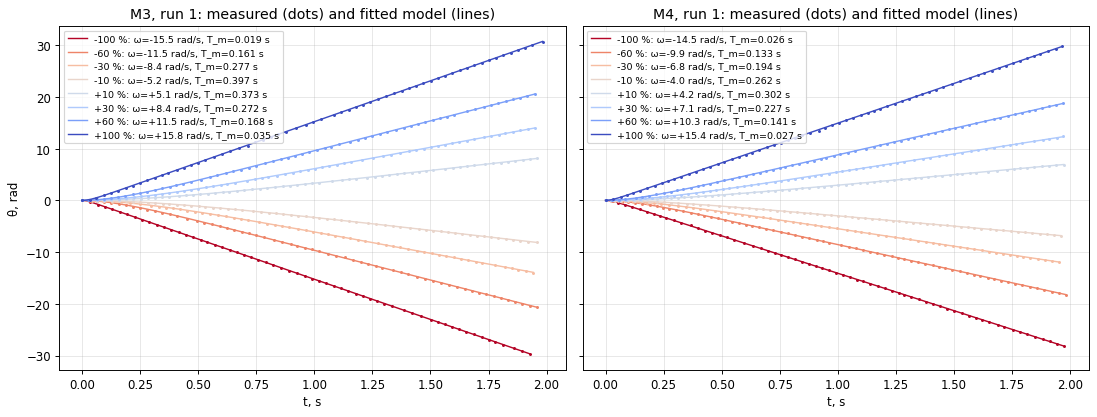

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
cmap = plt.get_cmap('coolwarm_r')
for ax, mot in zip(axes, MOTORS):
    for lv in levels[mot, 'run1']:
        pwm = int(lv['pwm'])
        if pwm not in (-100, -60, -30, -10, 10, 30, 60, 100):
            continue
        w, Tm = fits[mot, 'run1'].loc[pwm, ['w', 'Tm']]
        t_fit = np.linspace(0, lv['t'][-1], 200)
        color = cmap((pwm + 100) / 200)
        ax.plot(lv['t'], lv['theta'], '.', color=color, ms=3)
        ax.plot(t_fit, model(t_fit, w, Tm), color=color, lw=1.2, label=f'{pwm:+d} %: ω={w:+.1f} rad/s, T_m={Tm:.3f} s')
    ax.set(title=f'{mot}, run 1: measured (dots) and fitted model (lines)', xlabel='t, s')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel('θ, rad')
plt.tight_layout()

**Plot 2 — speed from PWM.** $\omega_{ss}$ against PWM, forward (blue) and backward (red), M3 squares, M4 circles, run 1. Lines: least-squares fits over $|\mathrm{PWM}|\ge 50\,\%$. Grey band: the dead zone lies within it.

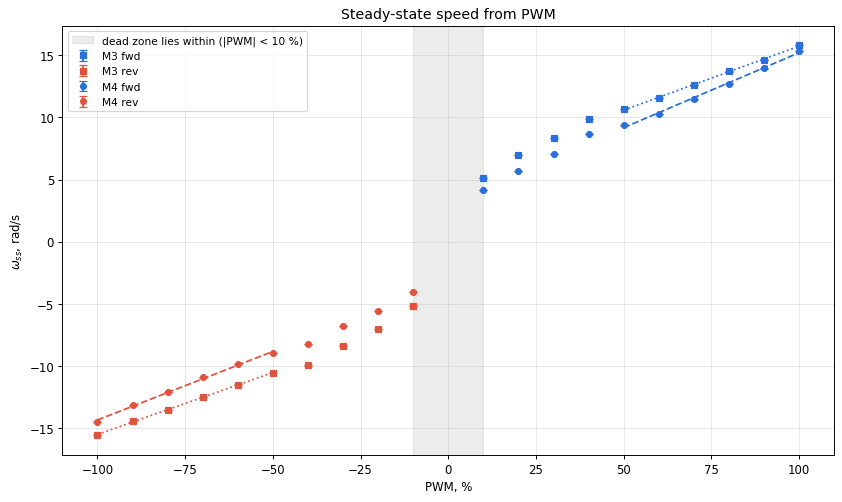

In [ ]:
plt.figure(figsize=(10, 6))
for mot in MOTORS:
    df = fits[mot, 'run1']
    for name, sign in [('fwd', 1), ('rev', -1)]:
        side = df[df.index * sign > 0]
        plt.errorbar(side.index, side.w, yerr=side.w_err, fmt=marker[mot], color=dir_color[name], ms=5, capsize=3, label=f'{mot} {name}')
        p = params[mot, name]
        x = side.index[np.abs(side.index) >= 50].values            # the linear part
        plt.plot(x, p['slope'] * x + p['b'], linestyle[mot], color=dir_color[name], lw=1.5)
dz = max(p['dz'] for p in params.values())
plt.axvspan(-dz, dz, color='grey', alpha=0.15, label=f'dead zone lies within (|PWM| < {dz:.0f} %)')
finish('Steady-state speed from PWM', 'PWM, %', r'$\omega_{ss}$, rad/s')

**Plot 3 — time constant from PWM.** $T_m$ with error bars (1 standard error from `pcov`), run 1, forward (blue) and backward (red), both motors.

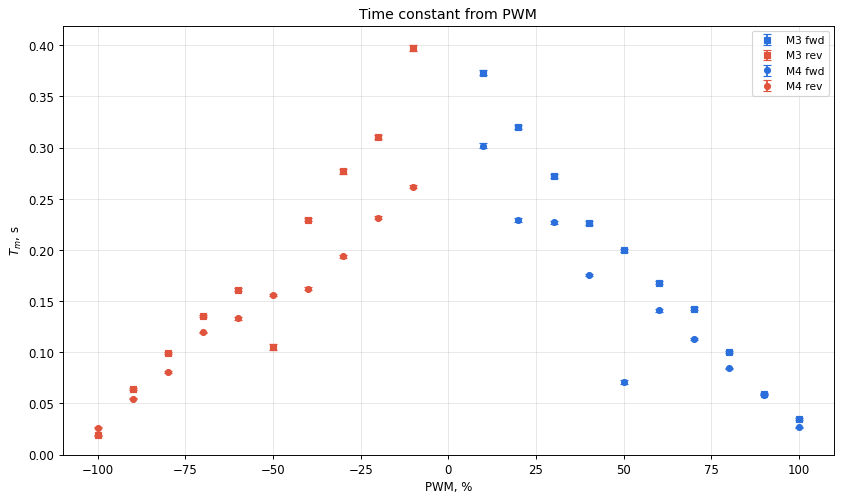

In [ ]:
plt.figure(figsize=(10, 6))
for mot in MOTORS:
    df = fits[mot, 'run1']
    for name, sign in [('fwd', 1), ('rev', -1)]:
        side = df[df.index * sign > 0]
        plt.errorbar(side.index, side.Tm, yerr=side.Tm_err, fmt=marker[mot], color=dir_color[name], ms=5, capsize=3, label=f'{mot} {name}')
finish('Time constant from PWM', 'PWM, %', r'$T_m$, s', ylim=(0, None))

## 5. Complex signals: model versus real motor

Each motor is simulated with the recorded input: the logged PWM (converted to volts) is interpolated with `np.interp` and the model solved with `odeint`. The model is $T_m\,\dot\omega = -\omega + U/k_e$, with the $k_e$ and $T_m$ of the commanded direction. **With dead zone:** $U = 0$ when $|\mathrm{PWM}|<10\,\%$. **Without:** the recorded $U$ is used down to PWM = 0.

Measured speed = `np.gradient` of the angle, smoothed with a centred **3-sample moving average** (≈ 0.15 s). Fit $= 100\,(1 - \lVert y-\hat y\rVert/\lVert y-\bar y\rVert)$.

In [ ]:
f0, f1, T_chirp = 0.2, 5, 12                                     # chirp settings of the .qrs program (Hz, Hz, s)


def load_signal(name):
    angle, time, pwm = read(name)
    return {'t': (time - time[0]) / 1000, 'theta': np.deg2rad(angle - angle[0]), 'pwm': pwm, 'U': pwm / 100 * U_bat[name]}


def simulate(mot, sig, dead_zone):
    def motor(state, t):
        speed, angle = state
        u = np.interp(t, sig['t'], sig['U'])                     # recorded input, in volts
        pwm = np.interp(t, sig['t'], sig['pwm'])
        p = params[mot, 'fwd' if pwm > 0 else 'rev']
        if dead_zone and abs(pwm) < p['dz']:
            u = 0                                                # the wheel does not move
        return [-speed / p['T_m'] + u / (p['T_m'] * p['k_e']), speed]
    return odeint(motor, [0, 0], sig['t'], hmax=0.005)[:, 1]    # simulated angle


def fit_percent(y, y_sim):
    return 100 * (1 - np.linalg.norm(y - y_sim) / np.linalg.norm(y - y.mean()))


def smooth(x, n=3):                                              # centred moving average over n samples
    return np.convolve(np.pad(x, n // 2, mode='edge'), np.ones(n) / n, mode='valid')


# what the model w_ss = U/k_e predicts, compared with the measured w_ss
for mot in MOTORS:
    df = fits[mot, 'run1']
    text = []
    for pwm in (-60, -10, 10, 60):
        p = params[mot, 'fwd' if pwm > 0 else 'rev']
        text.append(f'{pwm:+d} %: {df.loc[pwm, "U"] / p["k_e"]:.1f} vs {df.loc[pwm, "w"]:.1f}')
    print(f'{mot}: U/k_e vs measured w_ss, rad/s: ' + ', '.join(text))

signals = {(kind, mot): load_signal(f'{kind}_{mot}_{STUDENT}.txt') for kind in ['chirp', 'square'] for mot in MOTORS}
sims = {}
for (kind, mot), sig in signals.items():
    for dead_zone in [False, True]:
        sim = simulate(mot, sig, dead_zone)
        sims[kind, mot, dead_zone] = sim
        rmse = np.sqrt(np.mean((sim - sig['theta']) ** 2))
        print(f'{kind:6s} {mot}, {"with   " if dead_zone else "without"} dead zone: RMSE {rmse:.2f} rad, '
              f'fit {fit_percent(sig["theta"], sim):6.1f} %, final angle: measured {sig["theta"][-1]:.2f}, simulated {sim[-1]:.2f} rad')

M3: U/k_e vs measured w_ss, rad/s: -60 %: -6.0 vs -11.5, -10 %: -1.0 vs -5.2, +10 %: 1.0 vs 5.1, +60 %: 6.2 vs 11.5
M4: U/k_e vs measured w_ss, rad/s: -60 %: -6.6 vs -9.9, -10 %: -1.1 vs -4.0, +10 %: 1.2 vs 4.2, +60 %: 7.2 vs 10.3
chirp  M3, without dead zone: RMSE 2.57 rad, fit -102.5 %, final angle: measured 3.58, simulated 1.13 rad
chirp  M3, with    dead zone: RMSE 2.60 rad, fit -104.6 %, final angle: measured 3.58, simulated 1.12 rad
chirp  M4, without dead zone: RMSE 1.42 rad, fit  -16.1 %, final angle: measured 5.62, simulated 7.31 rad
chirp  M4, with    dead zone: RMSE 1.41 rad, fit  -15.1 %, final angle: measured 5.62, simulated 7.14 rad
square M3, without dead zone: RMSE 2.19 rad, fit  -36.0 %, final angle: measured -0.56, simulated -0.96 rad
square M3, with    dead zone: RMSE 2.19 rad, fit  -35.8 %, final angle: measured -0.56, simulated -0.95 rad
square M4, without dead zone: RMSE 1.24 rad, fit    4.6 %, final angle: measured 0.99, simulated 3.73 rad
square M4, with    dead

square M3: peak speed measured 10.2, simulated (with dead zone) 5.8 rad/s
square M4: peak speed measured 9.2, simulated (with dead zone) 7.1 rad/s


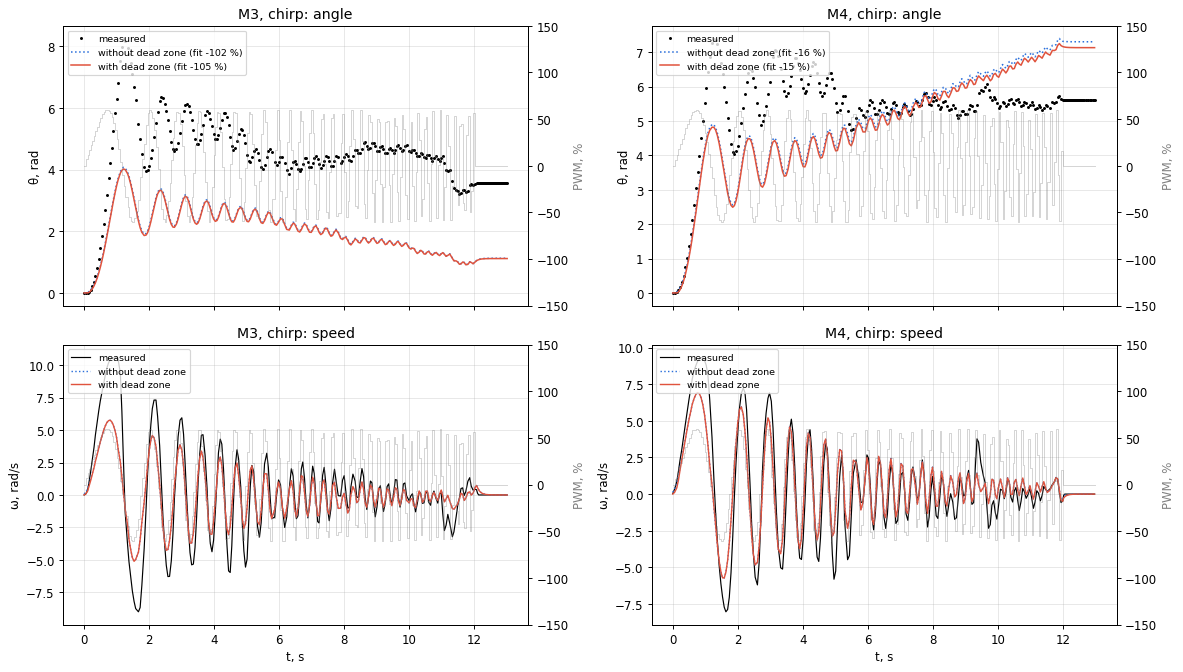

In [ ]:
#plot 4
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for col, mot in enumerate(MOTORS):
    sig = signals['chirp', mot]
    t, theta = sig['t'], sig['theta']
    ax_angle, ax_speed = axes[0, col], axes[1, col]
    ax_angle.plot(t, theta, 'k.', ms=3, label='measured')
    ax_speed.plot(t, smooth(np.gradient(theta, t)), 'k-', lw=1, label='measured')
    for dead_zone, style, color in [(False, ':', '#2a6fdb'), (True, '-', '#e0533d')]:
        sim = sims['chirp', mot, dead_zone]
        label = ('with' if dead_zone else 'without') + ' dead zone'
        ax_angle.plot(t, sim, style, color=color, lw=1.3, label=f'{label} (fit {fit_percent(theta, sim):.0f} %)')
        ax_speed.plot(t, smooth(np.gradient(sim, t)), style, color=color, lw=1.2, label=label)
    for ax, name, unit in [(ax_angle, 'angle', 'θ, rad'), (ax_speed, 'speed', 'ω, rad/s')]:
        ax_pwm = ax.twinx()                                      # input PWM on a second axis
        ax_pwm.step(t, sig['pwm'], where='post', color='grey', alpha=0.35, lw=0.8)
        ax_pwm.set_ylim(-150, 150)
        ax_pwm.set_ylabel('PWM, %', color='grey')
        ax.set(ylabel=unit, title=f'{mot}, chirp: {name}')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc='upper left')
    axes[1, col].set_xlabel('t, s')
plt.tight_layout()

for mot in MOTORS:                                               # square wave: numbers instead of a second plot
    sig = signals['square', mot]
    measured = np.abs(smooth(np.gradient(sig['theta'], sig['t']))).max()
    simulated = np.abs(smooth(np.gradient(sims['square', mot, True], sig['t']))).max()
    print(f'square {mot}: peak speed measured {measured:.1f}, simulated (with dead zone) {simulated:.1f} rad/s')

**Plot 5 — error (measured − simulated angle) over time.**

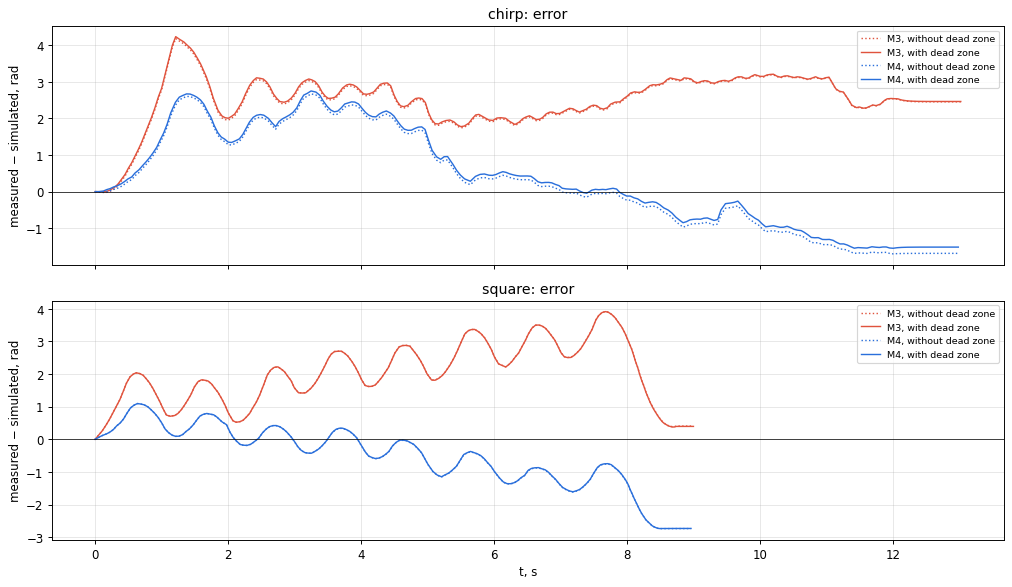

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, kind in zip(axes, ['chirp', 'square']):
    for mot in MOTORS:
        sig = signals[kind, mot]
        for dead_zone, style in [(False, ':'), (True, '-')]:
            error = sig['theta'] - sims[kind, mot, dead_zone]
            ax.plot(sig['t'], error, style, color=motor_color[mot], lw=1.2, label=f'{mot}, {"with" if dead_zone else "without"} dead zone')
    ax.axhline(0, color='k', lw=0.6)
    ax.set(ylabel='measured − simulated, rad', title=f'{kind}: error')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[-1].set_xlabel('t, s')
plt.tight_layout()

**Chirp: amplitude ratio vs frequency.** For each sample the speed and voltage amplitudes are taken over one chirp period around it, at $f(t) = f_0 + (f_1-f_0)\,t/T$, and compared with $1/(k_e\sqrt{1+(2\pi f T_m)^2})$.

M3: measured ratio 1.44 (f < 1 Hz, median), 1/k_e = 0.86 rad/s per V, corner 1/(2 pi T_m) = 1.48 Hz
M4: measured ratio 1.26 (f < 1 Hz, median), 1/k_e = 0.98 rad/s per V, corner 1/(2 pi T_m) = 1.80 Hz


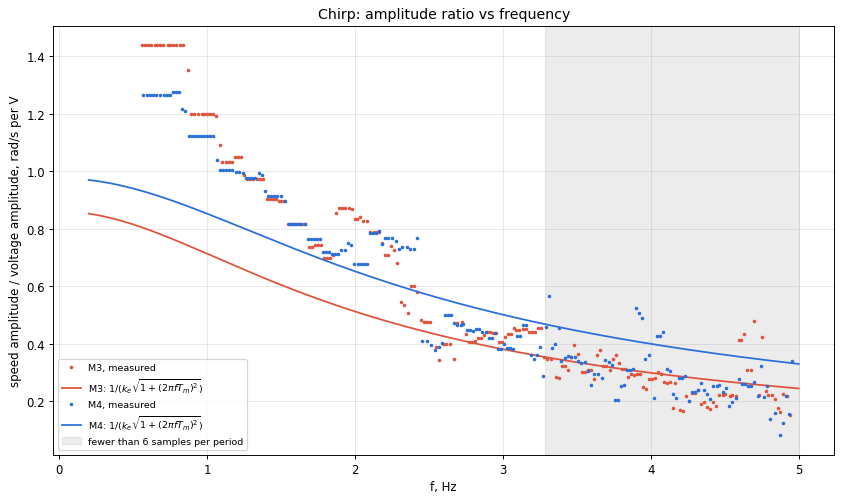

In [ ]:
plt.figure(figsize=(10, 6))
for mot in MOTORS:
    sig = signals['chirp', mot]
    t, U = sig['t'], sig['U']
    f = f0 + (f1 - f0) * t / T_chirp                             # instantaneous frequency, Hz
    speed = np.gradient(sig['theta'], t)
    ratio = np.full(len(t), np.nan)
    for k in range(len(t)):
        half_period = 0.5 / f[k]
        if t[k] - half_period >= 0 and t[k] + half_period <= T_chirp:      # one full period fits in the chirp
            window = np.abs(t - t[k]) <= half_period
            ratio[k] = np.ptp(speed[window]) / np.ptp(U[window])           # speed amplitude / voltage amplitude
    k_e = np.mean([params[mot, d]['k_e'] for d in ['fwd', 'rev']])
    T_m = np.mean([params[mot, d]['T_m'] for d in ['fwd', 'rev']])
    f_line = np.linspace(f0, f1, 200)
    plt.plot(f, ratio, '.', color=motor_color[mot], ms=4, label=f'{mot}, measured')
    plt.plot(f_line, 1 / (k_e * np.sqrt(1 + (2 * np.pi * f_line * T_m) ** 2)), color=motor_color[mot],
             label=f'{mot}: ' + r'$1/(k_e\sqrt{1+(2\pi f T_m)^2})$')
    print(f'{mot}: measured ratio {np.nanmedian(ratio[f < 1]):.2f} (f < 1 Hz, median), 1/k_e = {1 / k_e:.2f} rad/s per V, '
          f'corner 1/(2 pi T_m) = {1 / (2 * np.pi * T_m):.2f} Hz')
sample_rate = 1 / np.median(np.diff(signals['chirp', 'M3']['t']))
plt.axvspan(sample_rate / 6, f1, color='grey', alpha=0.15, label='fewer than 6 samples per period')
finish('Chirp: amplitude ratio vs frequency', 'f, Hz', 'speed amplitude / voltage amplitude, rad/s per V', legend=8)

## 6. Artifact analysis

**Zero drift.** The 3 s zero block at the start of each step file, the end of every coasting segment, the final angle after the series, and the first `time()` value.

M3 run1: zero block 90 samples, encoder 0..0 deg; first time() 71 ms; coasts ending at rest 20/20 (others [] deg); final angle +240 deg
M3 run2: zero block 96 samples, encoder 0..0 deg; first time() 71 ms; coasts ending at rest 15/20 (others [1.0, -1.0, 1.0, 1.0, 5.0] deg); final angle +856 deg
M4 run1: zero block 98 samples, encoder 0..0 deg; first time() 77 ms; coasts ending at rest 20/20 (others [] deg); final angle +663 deg
M4 run2: zero block 95 samples, encoder 0..0 deg; first time() 70 ms; coasts ending at rest 20/20 (others [] deg); final angle +672 deg
square M3: first time() 112 ms, last 10 samples (motor off) range 1 deg
square M4: first time() 109 ms, last 10 samples (motor off) range 0 deg
chirp M3: first time() 116 ms, last 10 samples (motor off) range 0 deg
chirp M4: first time() 115 ms, last 10 samples (motor off) range 0 deg


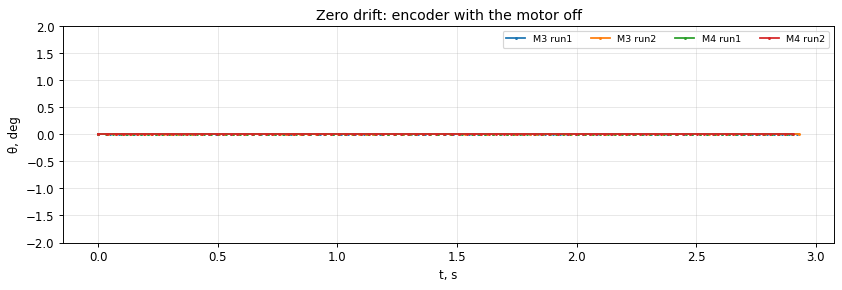

In [ ]:
plt.figure(figsize=(10, 3.5))
for (mot, run), name in FILES.items():
    angle, time, pwm = read(name)
    zero = time < 3000                                           # the 3 s zero block, motor off
    plt.plot((time[zero] - time[0]) / 1000, angle[zero], '.-', ms=3, label=f'{mot} {run}')
    coasts = read_segments(name)[2::2]
    changed = [c['angle'][-1] - c['angle'][-3] for c in coasts if c['angle'][-1] != c['angle'][-3]]   # still moving at the end
    print(f'{mot} {run}: zero block {zero.sum()} samples, encoder {angle[zero].min():.0f}..{angle[zero].max():.0f} deg; '
          f'first time() {time[0]:.0f} ms; coasts ending at rest {len(coasts) - len(changed)}/{len(coasts)} '
          f'(others {[float(c) for c in changed]} deg); final angle {angle[-1]:+.0f} deg')
for kind in ['square', 'chirp']:
    for mot in MOTORS:
        angle, time, pwm = read(f'{kind}_{mot}_{STUDENT}.txt')
        print(f'{kind} {mot}: first time() {time[0]:.0f} ms, last 10 samples (motor off) range {np.ptp(angle[-10:]):.0f} deg')
finish('Zero drift: encoder with the motor off', 't, s', 'θ, deg', legend=8, ncol=4, ylim=(-2, 2))

**Forward vs backward asymmetry, dead zone, saturation and motor-to-motor spread** (run 1).

In [ ]:
def percent(a, b):
    return f'{100 * (a / b - 1):+.1f} %'


for mot in MOTORS:
    fwd, rev = params[mot, 'fwd'], params[mot, 'rev']
    w = fits[mot, 'run1'].w
    same_pwm = [100 * (w.loc[p] / -w.loc[-p] - 1) for p in range(10, 101, 10)]      # |w_ss| forward vs backward
    print(f'{mot}: forward vs backward: slope {percent(fwd["slope"], rev["slope"])}, k_e {percent(fwd["k_e"], rev["k_e"])}, '
          f'T_m {percent(fwd["T_m"], rev["T_m"])}, dead zone < {fwd["dz"]:.0f} % / < {rev["dz"]:.0f} %; '
          f'|w_ss| at the same |PWM|: {min(same_pwm):+.1f} .. {max(same_pwm):+.1f} %')
    for name, sign in [('fwd', 1), ('rev', -1)]:                 # saturation: w_ss at +-100 % against the line through 50..90 %
        part = w[(sign * w.index >= 50) & (sign * w.index <= 90)]
        slope, b = np.polyfit(part.index, part.values, 1)
        print(f'   saturation {name}: w_ss at {sign * 100:+d} % is {percent(w.loc[sign * 100], slope * sign * 100 + b)} '
              f'from the line through 50..90 %')

for name in ['fwd', 'rev']:                                      # motor-to-motor spread
    m3, m4 = params['M3', name], params['M4', name]
    print(f'M3 vs M4 ({name}): slope {percent(m3["slope"], m4["slope"])}, k_e {percent(m3["k_e"], m4["k_e"])}, T_m {percent(m3["T_m"], m4["T_m"])}')
w3, w4 = fits['M3', 'run1'].w, fits['M4', 'run1'].w
print('w_ss M3 vs M4 at the same PWM: ' + ', '.join(f'{p:+d} %: {100 * (abs(w3[p]) / abs(w4[p]) - 1):+.0f} %' for p in w3.index))

M3: forward vs backward: slope +3.4 %, k_e -3.3 %, T_m +20.7 %, dead zone < 10 % / < 10 %; |w_ss| at the same |PWM|: -1.6 .. +1.6 %
   saturation fwd: w_ss at +100 % is +0.8 % from the line through 50..90 %
   saturation rev: w_ss at -100 % is +0.6 % from the line through 50..90 %
M4: forward vs backward: slope +9.3 %, k_e -8.5 %, T_m -13.3 %, dead zone < 10 % / < 10 %; |w_ss| at the same |PWM|: +2.1 .. +6.1 %
   saturation fwd: w_ss at +100 % is +2.3 % from the line through 50..90 %
   saturation rev: w_ss at -100 % is +2.0 % from the line through 50..90 %
M3 vs M4 (fwd): slope -14.7 %, k_e +16.7 %, T_m +42.7 %
M3 vs M4 (rev): slope -9.9 %, k_e +10.5 %, T_m +2.5 %
w_ss M3 vs M4 at the same PWM: -100 %: +7 %, -90 %: +10 %, -80 %: +12 %, -70 %: +14 %, -60 %: +17 %, -50 %: +18 %, -40 %: +21 %, -30 %: +23 %, -20 %: +26 %, -10 %: +30 %, +10 %: +23 %, +20 %: +22 %, +30 %: +18 %, +40 %: +14 %, +50 %: +14 %, +60 %: +13 %, +70 %: +10 %, +80 %: +8 %, +90 %: +5 %, +100 %: +3 %


**Coasting after power-off.** Angle turned in the 1 s after the motor is switched off, and the time until the wheel stops, compared with $T_m$.

M3: coasting 65..386 deg; the wheel stops 0.38..0.95 s after power-off (T_m 0.019..0.397 s)
M4: coasting 37..293 deg; the wheel stops 0.29..0.75 s after power-off (T_m 0.026..0.302 s)


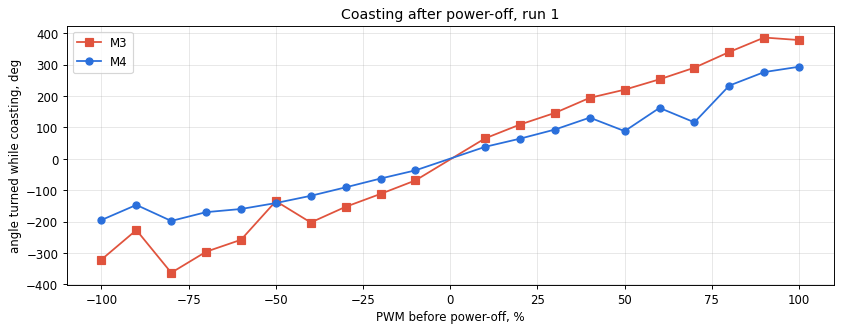

In [ ]:
plt.figure(figsize=(10, 4))
for mot in MOTORS:
    segments = read_segments(FILES[mot, 'run1'])
    pwm_before, turned, stop_time = [], [], []
    for on, coast in zip(segments[1::2], segments[2::2]):
        angle = coast['angle'] - on['angle'][-1]                 # deg turned after power-off
        t = (coast['time'] - on['time'][-1]) / 1000              # s after power-off
        moving = np.where(angle != angle[-1])[0]                 # samples before the encoder stops changing
        pwm_before.append(on['pwm'])
        turned.append(angle[-1])
        stop_time.append(t[moving[-1] + 1] if len(moving) else 0)
    plt.plot(pwm_before, turned, marker[mot] + '-', color=motor_color[mot], label=mot)
    Tm = fits[mot, 'run1'].Tm
    print(f'{mot}: coasting {np.abs(turned).min():.0f}..{np.abs(turned).max():.0f} deg; the wheel stops '
          f'{min(stop_time):.2f}..{max(stop_time):.2f} s after power-off (T_m {Tm.min():.3f}..{Tm.max():.3f} s)')
finish('Coasting after power-off, run 1', 'PWM before power-off, %', 'angle turned while coasting, deg', legend=10)

**Gear backlash.** At each reversal of the square wave, backlash would show as a flat region in the angle: the printout counts samples with no encoder change in the 5 intervals after each reversal.

In [ ]:
for mot in MOTORS:
    sig = signals['square', mot]
    angle, pwm = sig['theta'], sig['pwm']
    reversals = np.where((np.diff(np.sign(pwm)) != 0) & (pwm[1:] != 0))[0] + 1       # first sample after each reversal
    flat = [int(np.sum(np.diff(angle[k:k + 6]) == 0)) for k in reversals]
    print(f'{mot}: {len(reversals)} reversals; flat samples after each: {flat}')

M3: 15 reversals; flat samples after each: [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0]
M4: 15 reversals; flat samples after each: [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]


**Sampling jitter** (Δt against the 5 ms Timer) and **encoder quantisation / differentiation noise** (speed std on the steady last second of each level, with and without the 3-sample moving average).

In [ ]:
dt = {'steps': np.concatenate([np.diff(read(name)[1]) for name in FILES.values()])}
for kind in ['square', 'chirp']:
    dt[kind] = np.concatenate([np.diff(read(f'{kind}_{mot}_{STUDENT}.txt')[1]) for mot in MOTORS])
for name, d in dt.items():
    print(f'{name:6s}: dt mean {d.mean():.0f} ms, min {d.min():.0f} ms, max {d.max():.0f} ms  (Timer: 5 ms)')
dt_median = np.median(dt['steps'])
print(f'speed resolution of one 1 deg encoder step: 1 deg / {dt_median:.0f} ms = {np.deg2rad(1) / (dt_median / 1000):.2f} rad/s')

noise_raw, noise_smooth = [], []                                 # std of the speed on the steady part of each level
for mot in MOTORS:
    for lv in levels[mot, 'run1']:
        speed = np.gradient(lv['theta'], lv['t'])
        steady = lv['t'] > 1.0
        noise_raw.append(np.std(speed[steady][1:-1]))
        noise_smooth.append(np.std(smooth(speed)[steady][1:-1]))
print(f'speed noise (median over levels): raw {np.median(noise_raw):.2f} rad/s, 3-sample moving average {np.median(noise_smooth):.2f} rad/s')

steps : dt mean 32 ms, min 23 ms, max 110 ms  (Timer: 5 ms)
square: dt mean 49 ms, min 24 ms, max 96 ms  (Timer: 5 ms)
chirp : dt mean 51 ms, min 26 ms, max 94 ms  (Timer: 5 ms)
speed resolution of one 1 deg encoder step: 1 deg / 31 ms = 0.56 rad/s
speed noise (median over levels): raw 0.31 rad/s, 3-sample moving average 0.16 rad/s


In [ ]:
#battery voltage before/after each run
for name, (v_before, v_after) in battery.items():
    print(f'{name:28s} {v_before:.1f} -> {v_after:.1f} V')
for mot in MOTORS:
    run1, run2 = fits[mot, 'run1'], fits[mot, 'run2']
    high = np.abs(run1.index) >= 50
    gain1, gain2 = run1.w / run1.U, run2.w / run2.U              # speed per volt
    print(f'{mot}: speed per volt, run 2 vs run 1: {100 * np.mean(gain2[high] / gain1[high] - 1):+.1f} % (|PWM| >= 50 %), '
          f'{100 * np.mean(gain2[~high] / gain1[~high] - 1):+.1f} % (|PWM| < 50 %); '
          f'mean T_m (|PWM| >= 50 %): run 1 {run1.Tm[high].mean():.3f} s, run 2 {run2.Tm[high].mean():.3f} s')

steps_M4_run1_240069.txt     11.8 -> 11.8 V
steps_M4_run2_240069.txt     11.8 -> 11.8 V
square_M4_240069.txt         11.8 -> 11.8 V
chirp_M4_240069.txt          11.8 -> 11.8 V
steps_M3_run1_240069.txt     11.8 -> 11.7 V
steps_M3_run2_240069.txt     11.7 -> 11.7 V
square_M3_240069.txt         11.7 -> 11.7 V
chirp_M3_240069.txt          11.7 -> 11.7 V
M3: speed per volt, run 2 vs run 1: +1.9 % (|PWM| >= 50 %), +4.5 % (|PWM| < 50 %); mean T_m (|PWM| >= 50 %): run 1 0.107 s, run 2 0.118 s
M4: speed per volt, run 2 vs run 1: +0.9 % (|PWM| >= 50 %), +1.1 % (|PWM| < 50 %); mean T_m (|PWM| >= 50 %): run 1 0.089 s, run 2 0.099 s


In [ ]:
#Analysis


#1.How well does the first-order model with constant T_m and k_e describe the motor? Give the fit percentage on the complex signal and point to where the error is largest.

#The step fits with errors are below 0.03 rad/s for speed and below 0.005 s for T_m.
#The model fits the chirp and square wave poorly with fit without/with dead zone: chirp M3 -103%/-105%, chirp M4 -16%/-15%, square M3 -36%/-36%, square M4 +5%/+5%.
#None reach the 85% target.
#T_m is not constant: 0.26-0.40 s at ±10% PWM and 0.02-0.04 s at ±100%, but the model uses one mean value.
#The speed line has an intercept (±3-5.6 rad/s), but the model w = U/k_e goes through zero, so simulated speed is too low (about 1 rad/s at ±10% vs 4-5 rad/s measured).
#The error is largest at the first swings of the chirp and then add more in the angle (M3 chirp ends at 1.1 rad simulated vs 3.6 measured)

#2.Forward vs backward rotation: are the two directions the same motor? Should a controller use one set of parameters or two?

#M3 is almost symmetric with slope +3.4% (run 1) and -0.9% (run 2), but in run 2 forward is up to +7% faster at the same PWM.
#M4 is faster forward in both runs: |w_ss| +2-+7%, slope +9.3% (run 1) and +5.9% (run 2), k_e -8.5% (run 1).
#The T_m difference (+20.7% M3, -13.3% M4) is smaller than its spread (±0.04-0.06 s). Dead zone is below 10% in both directions.
#Two directions are almost the same motor for M3, but not for M4.
#A controller can use one set of parameters for M3, but two sets for M4.

#3.Which artifacts did you find, how large are they, and which of them matter for odometry next week?

#Zero drift.The encoder stays at 0 deg in the 3s zero block. The final angle after a series is not 0 (+240-+856 deg). time() starts at 70-116 ms, not 0.
#Dead zone below 10% PWM. No saturation (w_ss at ±100% is only +0.6-+2.3% off the line).
#The wheel turns 37-386 deg more and stops 0.29-0.95 s after power-off, much longer than T_m.
#Sampling interval is 32-51 ms instead of 5 ms. 1 deg per 31 ms gives 0.56 rad/s resolution.
#Battery 11.8 -> 11.7 V; speed per volt in run 2 vs run 1 differs by only +0.9-+4.5%.
#Speed noise is 0.31 rad/s without smoothing and 0.16 rad/s with the 3-sample average.
#M3 is faster than M4 at every level (+3-+30%), k_e +17% (fwd) and +11% (rev).

#4.Which complex signal did you choose and what did it show that the step series did not?

#I used the chirp and the square wave (A = 60%).
#The chirp shows the frequency response with  speed/voltage falls from 1.44 (M3) and 1.26 (M4) rad/s per V below 1 Hz to about 0.1-0.4 near 5 Hz (corner frequency 1.5 and 1.8 Hz).
#The measured ratio is above the model below 2 Hz because k_e ignores the intercept. The chirp crosses zero about 60 times, so the angle error adds up.
#The square wave shows reversals with no backlash and the model peak speed is too low (5.8 and 7.1 vs 10.2 and 9.2 rad/s).
#Steps cannot show that they have one operating point from rest, no frequency response and no reversals.